# Siamese evaluation on the complete held-out cohort

132 experimental images from 67 seeding configurations. This notebook reuses
the original Siamese checkpoint and the existing `cldm.preprocess` functions
with their original defaults. Preprocessed folders are constructed automatically.
Training is disabled by default; no image is preprocessed twice.

In [2]:
import os
import random
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from collections import defaultdict
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm


from cldm.config import EXP_FOLDER_TEST, SIM_FOLDER_TEST, MAIN_FOLDER,OUTPUT_DIR_CONTRASTIVE_LEARNING
from cldm.config import FPATH
from cldm.preprocess import preprocess_experimental_backgroundwhite_blackandwhite,preprocess_experimental_backgroundwhite, preprocess_simulation_graybackground, preprocess_simulation, preprocess_experimental_backgroundblack_blackandwhite, preprocess_experimental_backgroundblack_blackandwhite_nocropping


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
prop = fm.FontProperties(fname=str(FPATH),size=30)

# Data

The preprocessing is the same as the earlier 96-image analysis. The prepared
PNG folders are lossless outputs of the existing functions; dataset loaders then
use `preprocess_func=None` and retain the original 224×224 Siamese transform.
The functions, thresholds, crops and contrast settings in `cldm.preprocess` are
unchanged. See `siamese_full_test_132/preparation_settings.json` for the mapping.

Cross-source scoring includes all 132 images. Replicate/non-replicate histograms
use 65 configurations with two replicates, producing 65 similar and 65 dissimilar
pairs per source. Two singleton fixed configurations cannot supply replicate
pairs. Primary and fixed pair sets are constructed separately, preserving the
original primary selections while adding fixed configurations.

In [5]:
from pathlib import Path
import json
from prepare_siamese_full_test import (
    DEFAULT_OUTPUT_DIR, prepare_full_test, ordered_paths,
    generate_pairs, configuration_id, sha256, write_csv,
)

RESULTS_DIR = DEFAULT_OUTPUT_DIR
RUN_TRAINING = False
MAX_PAIR_PREVIEWS = 3  # Scores still use the complete cohort.
prepared_manifest, preparation_settings = prepare_full_test(output_dir=RESULTS_DIR)
OUTPUT_DIR_CONTRASTIVE_LEARNING = str(RESULTS_DIR / 'plots')
Path(OUTPUT_DIR_CONTRASTIVE_LEARNING).mkdir(exist_ok=True)

# Keep historical primary source order; fixed images follow the shared manifest.
alldata_exp = ordered_paths(prepared_manifest, 'experiment_binary_white_path', 'experiment_path')
alldata_exp_color = ordered_paths(prepared_manifest, 'experiment_grayscale_path', 'experiment_path')
alldata_sim = ordered_paths(prepared_manifest, 'simulation_grayscale_path', 'simulation_path')
alldata_pred = ordered_paths(prepared_manifest, 'prediction_binary_black_path', 'simulation_conditioned_path')
alldata_pred_color = ordered_paths(prepared_manifest, 'prediction_grayscale_path', 'simulation_conditioned_path')
alldata_exp_black = ordered_paths(prepared_manifest, 'experiment_binary_black_path', 'experiment_path')
alldata_sim_black = ordered_paths(prepared_manifest, 'simulation_binary_black_path', 'simulation_path')
for label, files in [('Experiments', alldata_exp), ('Simulations', alldata_sim),
                     ('Generated colony patterns', alldata_pred)]:
    assert len(files) == 132
    print(f'{label}: {len(files)} images')
print('Replicated configurations:', preparation_settings['replicated_configurations'])
print('Singleton images:', preparation_settings['singleton_images'])

Using verified prepared folders: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/controlnet_essential/siamese_full_test_132


Experiments: 132 images
Simulations: 132 images
Generated colony patterns: 132 images
Replicated configurations: 65
Singleton images: ['Fixed_12_1', 'Fixed_15_1']


# Dataset

In [6]:
# Dataset for training siamese network
class SiamesePairsDataset(Dataset):
    def __init__(self, pairs, labels, transform=None, preprocess_func=None):
        self.pairs = pairs
        self.labels = labels # binary
        self.transform = transform
        self.preprocess_func = preprocess_func

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        f1, f2 = self.pairs[idx]

        if self.preprocess_func:
            img1 = self.preprocess_func(f1)
            img2 = self.preprocess_func(f2)
            img1= Image.fromarray(img1).convert("L")
            img2= Image.fromarray(img2).convert("L")
        else:
            img1 = Image.open(f1).convert("L")
            img2 = Image.open(f2).convert("L")
            
        if self.transform:
            img1 = self.transform(img1)
            img2 = self.transform(img2)
        return img1, img2, torch.tensor(self.labels[idx], dtype=torch.float32)

# Pair generation now comes from prepare_siamese_full_test.generate_pairs.
# It recognizes Fixed_N identifiers and preserves original primary selections.

In [7]:
transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])

if RUN_TRAINING:
    # Generate training data and split
    primary_training_simulations = [os.path.join(SIM_FOLDER_TEST, f) for f in os.listdir(SIM_FOLDER_TEST) if f.endswith('.TIF')]
    all_pairs, all_labels = generate_pairs(primary_training_simulations) # use binary simulation image pairs
    split_ratio = 0.2
    train_pairs, test_pairs, train_labels, test_labels = train_test_split(all_pairs, all_labels, test_size=split_ratio, random_state=42, stratify=all_labels)
    
    
    # create datasets and dataloaders  # training with gray background simulations used in the paper
    train_dataset = SiamesePairsDataset(train_pairs, train_labels, transform=transform, preprocess_func=preprocess_simulation_graybackground)
    test_dataset = SiamesePairsDataset(test_pairs, test_labels, transform=transform, preprocess_func=preprocess_simulation_graybackground)
    
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    
    print(f"Total pairs: {len(all_pairs)} (Train: {len(train_dataset)}, Test: {len(test_dataset)})")
else:
    train_loader = test_loader = None
    print('Using the saved Siamese checkpoint; no training or new validation split.')

Using the saved Siamese checkpoint; no training or new validation split.


# Train

In [8]:
class SiameseNet(nn.Module):
    def __init__(self):
        super(SiameseNet, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 16, 3), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.fc = nn.Sequential(
            nn.Linear(32 * 54 * 54, 128),
            nn.ReLU(),
            nn.Linear(128, 64)
        )

    def forward_once(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

    def forward(self, x1, x2):
        out1 = self.forward_once(x1)
        out2 = self.forward_once(x2)
        return out1, out2

def contrastive_loss(out1, out2, label, margin=1.0):
    d = F.pairwise_distance(out1, out2)
    loss = torch.mean(label * torch.pow(d, 2) + (1 - label) * torch.pow(torch.clamp(margin - d, min=0.0), 2))
    return loss


In [9]:
if RUN_TRAINING:
    model = SiameseNet().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    epochs = 10
    patience = 10  # early stopping
    min_delta = 1e-4  # early stopping
    
    best_test_loss = float('inf')
    early_stop_counter = 0
    
    for epoch in range(1, epochs + 1):
        # Train
        model.train()
        total_train_loss = 0
        for img1, img2, label in train_loader:
            img1, img2, label = img1.to(device), img2.to(device), label.to(device)
            out1, out2 = model(img1, img2)
            loss = contrastive_loss(out1, out2, label)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item()
    
        avg_train_loss = total_train_loss / len(train_loader)
    
        # Validate
        model.eval()
        total_test_loss = 0
        with torch.no_grad():
            for img1, img2, label in test_loader:
                img1, img2, label = img1.to(device), img2.to(device), label.to(device)
                out1, out2 = model(img1, img2)
                loss = contrastive_loss(out1, out2, label)
                total_test_loss += loss.item()
    
        avg_test_loss = total_test_loss / len(test_loader)
        print(f"Epoch {epoch} | Train Loss: {avg_train_loss:.4f}, Test Loss: {avg_test_loss:.4f}")
    
        # Early stopping
        if avg_test_loss + min_delta < best_test_loss:
            best_test_loss = avg_test_loss
            early_stop_counter = 0
            torch.save(model.state_dict(), "best_model.pth")  # save best model
        else:
            early_stop_counter += 1
            if early_stop_counter >= patience:
                print(f"Early stopping.")
                break
else:
    print('Training disabled; existing checkpoint is unchanged.')

Training disabled; existing checkpoint is unchanged.


In [10]:
if RUN_TRAINING:
    model_dir = OUTPUT_DIR_CONTRASTIVE_LEARNING
    os.makedirs(model_dir, exist_ok=True)
    model_path = os.path.join(model_dir, "model.pth")
    torch.save(model, model_path)
    print(f"Model saved to {model_path}")
else:
    print('Training disabled; existing checkpoint is unchanged.')

Training disabled; existing checkpoint is unchanged.


In [11]:
# Use exactly the checkpoint used for the existing Supplementary Figures 20–21.
model_path = str(Path(__file__).parent) if '__file__' in globals() else ''
model_path = str(Path.cwd() / 'contrastive_learning_v20251114_1234/model.pth')
checkpoint_hash_before = sha256(model_path)
model = torch.load(model_path, map_location=device)
model = model.to(device).eval()
print('Checkpoint:', model_path)
print('SHA256:', checkpoint_hash_before)

Checkpoint: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/controlnet_essential/contrastive_learning_v20251114_1234/model.pth
SHA256: 011214725f368f2219d05423f207282fd049c6b5c6dcf132b4c79b423485a2da


# Scoring

In [12]:
def plot_test_pairs(model, data_loader, device, num_pairs=5):
    model.eval()
    shown = 0

    with torch.no_grad():
        for img1, img2, label in data_loader:
            img1, img2 = img1.to(device), img2.to(device)
            out1, out2 = model(img1, img2)
            distances = F.pairwise_distance(out1, out2).cpu().numpy()
            labels = label.numpy()
            imgs1 = img1.cpu()
            imgs2 = img2.cpu()

            for i in range(len(distances)):
                if shown >= num_pairs:
                    return
                fig, axs = plt.subplots(1, 2, figsize=(4, 2))
                axs[0].imshow(imgs1[i][0], cmap='gray')
                axs[0].set_title("Image 1")
                axs[0].axis('off')
                axs[1].imshow(imgs2[i][0], cmap='gray')
                axs[1].set_title("Image 2")
                axs[1].axis('off')
                if int(labels[i]) == 1:
                  label = "Identical"
                elif int(labels[i]) == 0:
                  label = "Different"
                plt.suptitle(f"Label: {label}, Dissimilarity: {distances[i]:.4f}")
                plt.tight_layout()
                plt.show()
                shown += 1


## Test set

In [13]:
if test_loader is not None:
    plot_test_pairs(model, test_loader, device, num_pairs=MAX_PAIR_PREVIEWS)
else:
    print('Historical validation preview skipped; full-cohort evaluation follows.')

Historical validation preview skipped; full-cohort evaluation follows.


## Experiment set

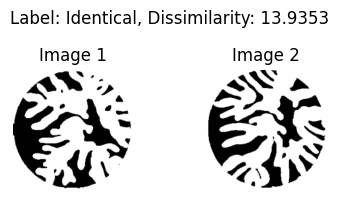

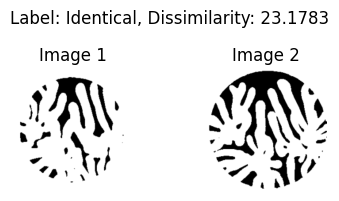

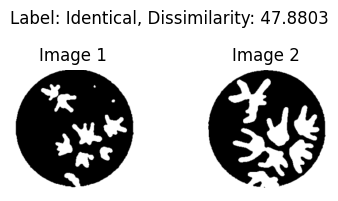

In [14]:
# Now use the trained model on image pairs from different sources

# Generate balanced pairs from experimental data
exp_pairs, exp_labels = generate_pairs(alldata_exp, seed=0)

# Create Dataset and DataLoader
exp_dataset = SiamesePairsDataset(exp_pairs, exp_labels, transform=transform, preprocess_func=None)
exp_loader = DataLoader(exp_dataset, batch_size=32, shuffle=False)

# Plot results

plot_test_pairs(model, exp_loader, device, num_pairs=MAX_PAIR_PREVIEWS)

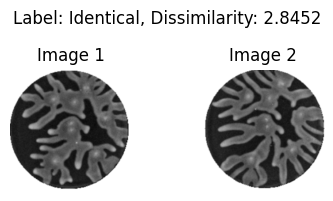

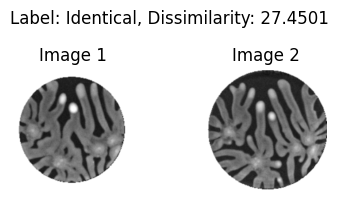

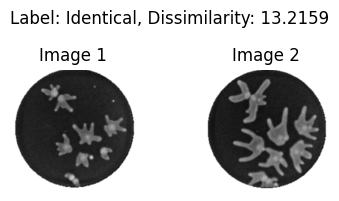

In [15]:
# On grayscale experimental images

# Generate balanced pairs from experimental data
exp_pairs_color, exp_labels_color = generate_pairs(alldata_exp_color, seed=0)

# Create Dataset and DataLoader
exp_dataset_color  = SiamesePairsDataset(exp_pairs_color, exp_labels_color , transform=transform,preprocess_func=None)
exp_loader_color = DataLoader(exp_dataset_color , batch_size=32, shuffle=False)

# Plot results
plot_test_pairs(model, exp_loader_color, device, num_pairs=MAX_PAIR_PREVIEWS)

## Simulation set

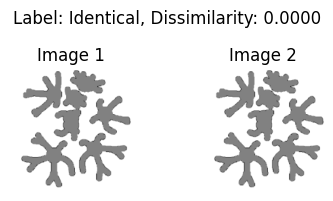

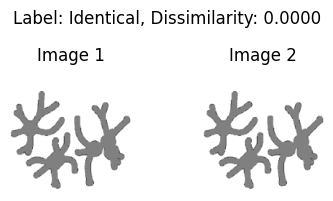

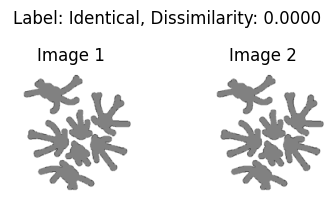

In [16]:
# Generate balanced pairs from simulation data
sim_pairs, sim_labels = generate_pairs(alldata_sim, seed=0)


# Create Dataset and DataLoader
sim_dataset  = SiamesePairsDataset(sim_pairs, sim_labels , transform=transform, preprocess_func=None)
sim_loader = DataLoader(sim_dataset , batch_size=32, shuffle=False)

# Plot results

plot_test_pairs(model, sim_loader, device, num_pairs=MAX_PAIR_PREVIEWS)

## Prediction set

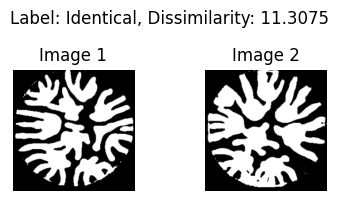

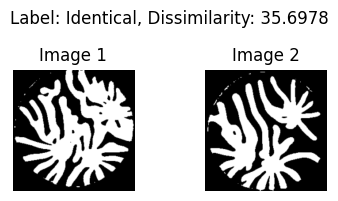

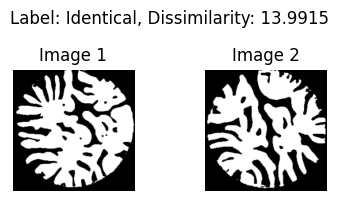

In [17]:
# Generate balanced pairs from prediction data
pred_pairs, pred_labels = generate_pairs(alldata_pred, seed=0)

# Create Dataset and DataLoader
pred_dataset = SiamesePairsDataset(pred_pairs, pred_labels, transform=transform, preprocess_func=None)
pred_loader = DataLoader(pred_dataset, batch_size=32, shuffle=False)

# Plot results
plot_test_pairs(model, pred_loader, device, num_pairs=MAX_PAIR_PREVIEWS)

Prediction grayscale


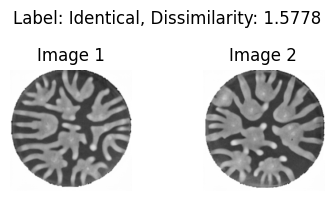

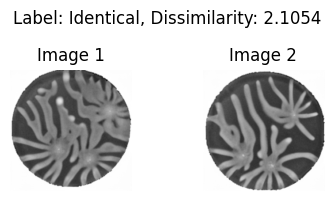

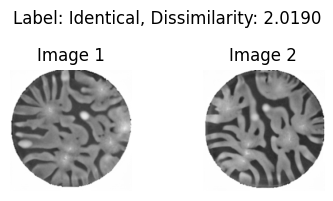

In [18]:
# Generate balanced pairs from prediction data
pred_pairs_color, pred_labels_color = generate_pairs(alldata_pred_color, seed=0)

# Create Dataset and DataLoader
pred_dataset_color = SiamesePairsDataset(pred_pairs_color, pred_labels_color, transform=transform, preprocess_func=None)
pred_loader_color = DataLoader(pred_dataset_color, batch_size=32, shuffle=False)

# Plot results
plot_test_pairs(model, pred_loader_color, device, num_pairs=MAX_PAIR_PREVIEWS)

# Score histograms

In [19]:
def get_scores_by_label(model, loader, device):
    model.eval()
    scores_label_0 = []
    scores_label_1 = []

    with torch.no_grad():
        for img1, img2, label in loader:
            img1, img2, label = img1.to(device), img2.to(device), label.to(device)
            out1, out2 = model(img1, img2)
            distances = F.pairwise_distance(out1, out2)

            for d, l in zip(distances.cpu().numpy(), label.cpu().numpy()):
                if int(l) == 1:
                    scores_label_1.append(d)
                else:
                    scores_label_0.append(d)

    return scores_label_0, scores_label_1

def plot_score_histograms(scores_0, scores_1, title, output_dir, bins=30):
    plt.figure(figsize=(5, 4))
    plt.hist(scores_0, bins=bins, alpha=0.7, label="Label 0 (dissimilar)", density=True)
    plt.hist(scores_1, bins=bins, alpha=0.7, label="Label 1 (identical)", density=True)
    plt.xlabel("Dissimilarity")
    plt.ylabel("Density")
    plt.title(f"{title}")
    plt.legend()
    plt.tight_layout()
    filename = os.path.join(output_dir, f"{title}.png")
    plt.savefig(filename)
    plt.show()


def plot_score_histograms_subplots(scores_0, scores_1, title, output_dir, bins=30):

    fig = plt.figure(figsize=(16, 12))
    
    plt.subplot(2,2,1)
    plt.hist(scores_0[0], bins=bins, alpha=0.7, label="Label 0 (dissimilar)", density=True)
    plt.hist(scores_1[0], bins=bins, alpha=0.7, label="Label 1 (identical)", density=True)
    plt.xlabel("Dissimilarity", fontsize=30,fontproperties=prop)
    plt.ylabel("Density", fontsize=30,fontproperties=prop)
    plt.title(f"{title[0]}", fontproperties=prop,fontsize=30)
    plt.xticks([0,10,30,50,70], fontproperties=prop,fontsize=30)
    plt.yticks([0,0.1,0.2],fontproperties=prop,fontsize=30)
    # plt.legend(prop=prop) 
    plt.tight_layout()
  

    plt.subplot(2,2,2)
    plt.hist(scores_0[1], bins=bins, alpha=0.7, label="Label 0 (dissimilar)", density=True)
    plt.hist(scores_1[1], bins=bins, alpha=0.7, label="Label 1 (identical)", density=True)
    plt.xlabel("Dissimilarity", fontsize=30,fontproperties=prop)
    plt.ylabel("Density", fontsize=30,fontproperties=prop)
    plt.title(f"{title[1]}", fontproperties=prop,fontsize=30)
    plt.xticks([0,50,100,150], fontproperties=prop,fontsize=30)
    plt.yticks([0,0.03,0.06],fontproperties=prop,fontsize=30)
    # plt.legend(prop=prop) 
    plt.tight_layout()
    

    plt.subplot(2,2,3)
    plt.hist(scores_0[2], bins=bins, alpha=0.7, label="Label 0 (dissimilar)", density=True)
    plt.hist(scores_1[2], bins=bins, alpha=0.7, label="Label 1 (identical)", density=True)
    plt.xlabel("Dissimilarity", fontsize=30,fontproperties=prop)
    plt.ylabel("Density", fontsize=30,fontproperties=prop)
    plt.title(f"{title[2]}", fontproperties=prop,fontsize=30)
    plt.xticks([4,8,12,16], fontproperties=prop,fontsize=30)
    plt.yticks([0,0.2,0.4],fontproperties=prop,fontsize=30)
    # plt.legend(prop=prop) 
    plt.tight_layout()
    

    plt.subplot(2,2,4)
    plt.hist(scores_0[3], bins=bins, alpha=0.7, label="Label 0 (dissimilar)", density=True)
    plt.hist(scores_1[3], bins=bins, alpha=0.7, label="Label 1 (identical)", density=True)
    plt.xlabel("Dissimilarity", fontsize=30,fontproperties=prop)
    plt.ylabel("Density", fontsize=30,fontproperties=prop)
    plt.title(f"{title[3]}", fontproperties=prop,fontsize=30)
    plt.xticks([0,20,40,60], fontproperties=prop,fontsize=30)
    plt.yticks([0,0.02,0.04,0.06,0.08],fontproperties=prop,fontsize=30)
    # plt.legend(prop=prop) 
    plt.tight_layout()

    handles, labels = plt.gca().get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=18, 
               prop=prop, bbox_to_anchor=(0.55, -0.07), frameon=False)
    
    
    filename = os.path.join(output_dir, f"{title[0]}_{title[1]}_{title[2]}_{title[3]}.png")

    plt.savefig(filename)
    plt.show()


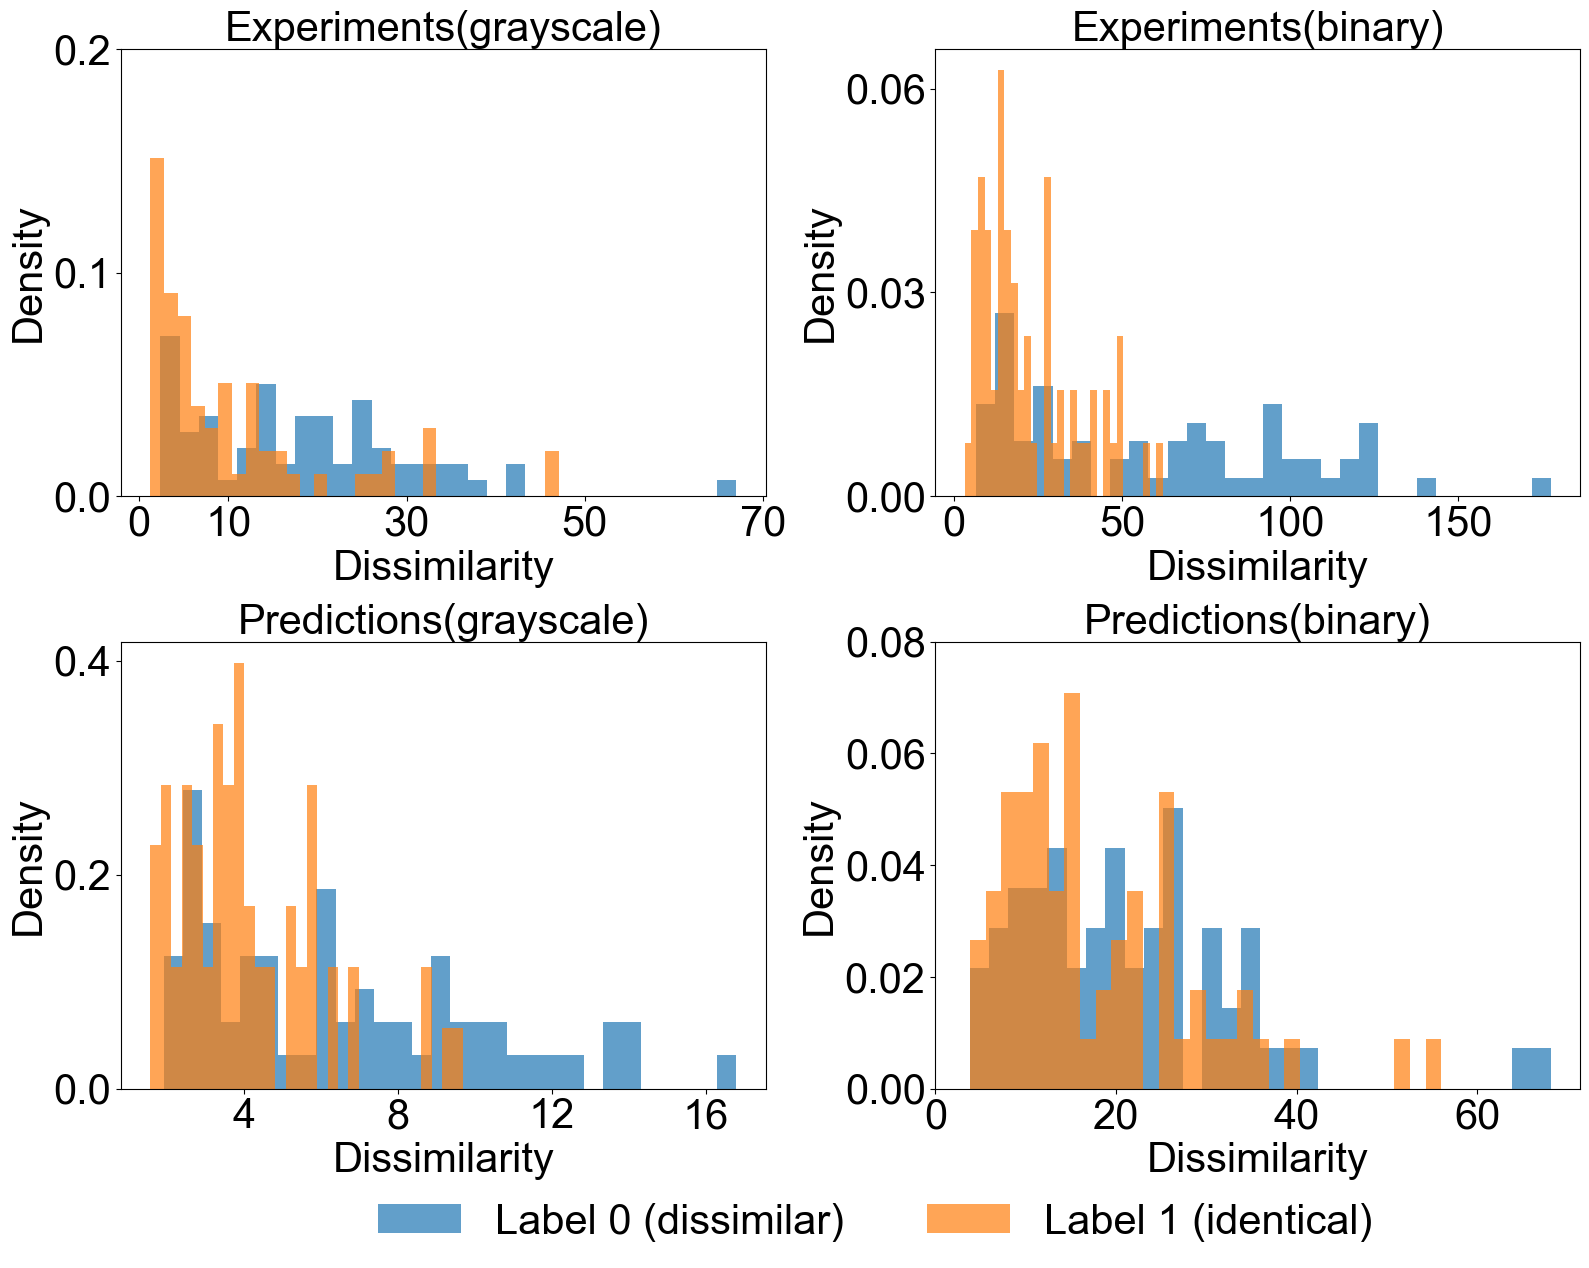

In [20]:
# Experiment in colors
scores_0a, scores_1a = get_scores_by_label(model, exp_loader_color, device)

# Experiment in binary
scores_0b, scores_1b = get_scores_by_label(model, exp_loader, device)

# Prediction in binary
scores_0c, scores_1c = get_scores_by_label(model, pred_loader, device)

# Prediction in color
scores_0d, scores_1d = get_scores_by_label(model, pred_loader_color, device)

titles= ["Experiments(grayscale)","Experiments(binary)","Predictions(grayscale)","Predictions(binary)"]

# Keep prediction grayscale before prediction binary, matching the titles.
scores_0=[scores_0a,scores_0b,scores_0d,scores_0c]
scores_1=[scores_1a,scores_1b,scores_1d,scores_1c]

plot_score_histograms_subplots(scores_0, scores_1, titles, OUTPUT_DIR_CONTRASTIVE_LEARNING)

In [21]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Supp. Fig. 20 — four replicate/non-replicate histograms
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'sim_to_exp_diffusion' / 'vector based plots'

import shutil
previous_exports = RESULTS_DIR / 'previous_exports'
previous_exports.mkdir(exist_ok=True)
for name in ['SuppFig20_dissimilarity_histograms.pdf',
             'SuppFig21_distance_difference_histogram.pdf',
             'SuppFig20_21_source_audit.json', 'SuppFig20_prediction_order_fix.json']:
    path = VECTOR_DIR / name
    if path.exists() and not (previous_exports / name).exists():
        shutil.copy2(path, previous_exports / name)


# Reuse computed scores; no Siamese training or inference is repeated.
def _vector_plot_score_histograms_subplots(scores_0, scores_1, title, output_dir, bins=30):

    fig = plt.figure(figsize=(16, 12))
    
    plt.subplot(2,2,1)
    plt.hist(scores_0[0], bins=bins, alpha=0.7, label="Label 0 (dissimilar)", density=True)
    plt.hist(scores_1[0], bins=bins, alpha=0.7, label="Label 1 (identical)", density=True)
    plt.xlabel("Dissimilarity", fontsize=30,fontproperties=prop)
    plt.ylabel("Density", fontsize=30,fontproperties=prop)
    plt.title(f"{title[0]}", fontproperties=prop,fontsize=30)
    plt.xticks([0,10,30,50,70], fontproperties=prop,fontsize=30)
    plt.yticks([0,0.1,0.2],fontproperties=prop,fontsize=30)
    # plt.legend(prop=prop) 
    plt.tight_layout()
  

    plt.subplot(2,2,2)
    plt.hist(scores_0[1], bins=bins, alpha=0.7, label="Label 0 (dissimilar)", density=True)
    plt.hist(scores_1[1], bins=bins, alpha=0.7, label="Label 1 (identical)", density=True)
    plt.xlabel("Dissimilarity", fontsize=30,fontproperties=prop)
    plt.ylabel("Density", fontsize=30,fontproperties=prop)
    plt.title(f"{title[1]}", fontproperties=prop,fontsize=30)
    plt.xticks([0,50,100,150], fontproperties=prop,fontsize=30)
    plt.yticks([0,0.03,0.06],fontproperties=prop,fontsize=30)
    # plt.legend(prop=prop) 
    plt.tight_layout()
    

    plt.subplot(2,2,3)
    plt.hist(scores_0[2], bins=bins, alpha=0.7, label="Label 0 (dissimilar)", density=True)
    plt.hist(scores_1[2], bins=bins, alpha=0.7, label="Label 1 (identical)", density=True)
    plt.xlabel("Dissimilarity", fontsize=30,fontproperties=prop)
    plt.ylabel("Density", fontsize=30,fontproperties=prop)
    plt.title(f"{title[2]}", fontproperties=prop,fontsize=30)
    plt.xticks([4,8,12,16], fontproperties=prop,fontsize=30)
    plt.yticks([0,0.2,0.4],fontproperties=prop,fontsize=30)
    # plt.legend(prop=prop) 
    plt.tight_layout()
    

    plt.subplot(2,2,4)
    plt.hist(scores_0[3], bins=bins, alpha=0.7, label="Label 0 (dissimilar)", density=True)
    plt.hist(scores_1[3], bins=bins, alpha=0.7, label="Label 1 (identical)", density=True)
    plt.xlabel("Dissimilarity", fontsize=30,fontproperties=prop)
    plt.ylabel("Density", fontsize=30,fontproperties=prop)
    plt.title(f"{title[3]}", fontproperties=prop,fontsize=30)
    plt.xticks([0,20,40,60], fontproperties=prop,fontsize=30)
    plt.yticks([0,0.02,0.04,0.06,0.08],fontproperties=prop,fontsize=30)
    # plt.legend(prop=prop) 
    plt.tight_layout()

    handles, labels = plt.gca().get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=18, 
               prop=prop, bbox_to_anchor=(0.55, -0.07), frameon=False)
    
    
    filename = os.path.join(output_dir, f"{title[0]}_{title[1]}_{title[2]}_{title[3]}.png")

    save_vector_pdf(fig, VECTOR_DIR / 'SuppFig20_dissimilarity_histograms.pdf')
    plt.close(fig)


_vector_plot_score_histograms_subplots(
    [scores_0a, scores_0b, scores_0d, scores_0c],
    [scores_1a, scores_1b, scores_1d, scores_1c],
    titles, VECTOR_DIR,
)

Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig20_dissimilarity_histograms.pdf


In [22]:
if test_loader is not None:
    # Test set
    scores_0, scores_1 = get_scores_by_label(model, test_loader, device)
    
    # Plot
    plot_score_histograms(scores_0, scores_1, "Test dataset", OUTPUT_DIR_CONTRASTIVE_LEARNING)

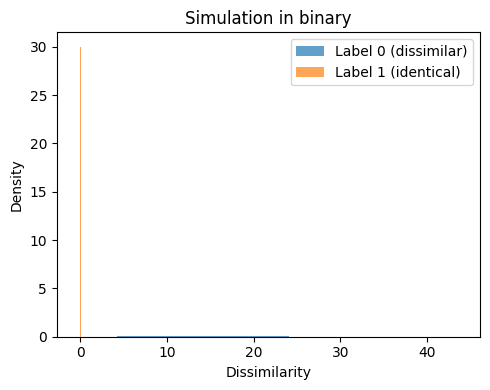

In [23]:
# Simulation set
scores_0, scores_1 = get_scores_by_label(model, sim_loader, device)


# Plot
plot_score_histograms(scores_0, scores_1, "Simulation in binary", OUTPUT_DIR_CONTRASTIVE_LEARNING)


In [24]:
if test_loader is not None:
    # Test set
    scores_0, scores_1 = get_scores_by_label(model, test_loader, device)
    
    # Plot
    plot_score_histograms(scores_0, scores_1, "Test dataset", OUTPUT_DIR_CONTRASTIVE_LEARNING)

# Compare prediction-experiments vs simulation-experiments

In [25]:
# Generate image pairs, one from experiment, one from either prediction or simulation
class FixedPairDataset(Dataset):
    def __init__(self, exp_files, ref_files, transform=None, seed=42, image_size=(64, 64), preprocess_func_1=None, preprocess_func_2=None):
        self.transform = transform
        self.image_size = image_size
        self.pairs = []
        self.preprocess_func_1 = preprocess_func_1
        self.preprocess_func_2 = preprocess_func_2

        # Group references by ExpID
        ref_group = defaultdict(list)
        for f in ref_files:
            expid = configuration_id(f)
            ref_group[expid].append(f)

        random.seed(seed)

        for exp_f in exp_files:
            expid = configuration_id(exp_f)
            if expid in ref_group and len(ref_group[expid]) > 0:
                ref_f = random.choice(ref_group[expid])
            else:
                raise FileNotFoundError(f'No matching reference for {exp_f}')

            self.pairs.append((ref_f, exp_f))

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        f1, f2 = self.pairs[idx]

        f1_name = os.path.basename(f1)

        if self.preprocess_func_2 is not None:
            img2 = self.preprocess_func_2(f2)
            img2= Image.fromarray(img2).convert("L")
            if self.preprocess_func_1 is not None:
                img1=self.preprocess_func_1(f1)
                img1= Image.fromarray(img1).convert("L")
            else:
                img1 = Image.open(f1).convert('L')
                
        else:
            img2 = Image.open(f2).convert('L')
            if self.preprocess_func_1 is not None:
                img1=self.preprocess_func_1(f1)
                img1= Image.fromarray(img1).convert("L")
            else:
                img1 = Image.open(f1).convert('L')      

       
        
           

      
        f1_name = os.path.basename(f1)

        if self.transform:
            img1 = self.transform(img1)
            img2 = self.transform(img2)

        return img1, img2, f1_name, os.path.basename(f2)

In [26]:
def compare_and_plot_by_index(model, sim_dataset, pred_dataset, device, output_dir, num_pairs=10, max_previews=MAX_PAIR_PREVIEWS):
    model.eval()
    sim_score_list = []
    pred_score_list = []

    print(f"Comparing up to {num_pairs} pairs (available: {len(sim_dataset)})")
    count = 0
    with torch.no_grad():
        for i in range(min(num_pairs, len(sim_dataset), len(pred_dataset))):
            img1_sim, img2_sim, name1_sim, name2_sim = sim_dataset[i]
            img1_pred, img2_pred, name1_pred, name2_pred = pred_dataset[i]

            # Skip mismatched experimental images (likely due to missing replicates)
            if name2_sim != name2_pred:
                print(f"[{i}] Skipping mismatched exp image: SIM = {name2_sim}, PRED = {name2_pred}")
                continue

            # Move to device
            img1_sim = img1_sim.unsqueeze(0).to(device)
            img2_sim = img2_sim.unsqueeze(0).to(device)
            img1_pred = img1_pred.unsqueeze(0).to(device)
            img2_pred = img2_pred.unsqueeze(0).to(device)

            # Compute distances
            out_sim1, out_sim2 = model(img1_sim, img2_sim)
            out_pred1, out_pred2 = model(img1_pred, img2_pred)

            d_sim = F.pairwise_distance(out_sim1, out_sim2).item()
            d_pred = F.pairwise_distance(out_pred1, out_pred2).item()
            if d_sim > d_pred: count += 1
            sim_score_list.append(d_sim)
            pred_score_list.append(d_pred)

            if i >= max_previews:
                continue

            # Plot side by side
            fig, axs = plt.subplots(1, 3, figsize=(9, 3))

            axs[0].imshow(img1_sim.cpu().squeeze(), cmap='gray')
            axs[0].set_title(f"Sim vs Exp\nDissimilarity: {d_sim:.4f}\nref: {name1_sim}, exp: {name2_sim}")
            axs[0].axis('off')

            axs[1].imshow(img1_pred.cpu().squeeze(), cmap='gray')
            axs[1].set_title(f"Pred vs Exp\nDissimilarity: {d_pred:.4f}\nref: {name1_pred}, exp: {name2_pred}")
            axs[1].axis('off')

            axs[2].imshow(img2_pred.cpu().squeeze(), cmap='gray')
            axs[2].set_title(f"Exp: {name2_pred}")
            axs[2].axis('off')

            plt.suptitle(f"Experiment ID: {name2_sim.split('_')[0]}")
            plt.tight_layout()

            filename = os.path.join(output_dir, f"{i}_{name2_sim.replace('/', '_')}.png")
            plt.savefig(filename)

            plt.show()

    return sim_score_list, pred_score_list

Total experimental images paired: 132 (simulation), 132 (prediction)
Comparing up to 132 pairs (available: 132)


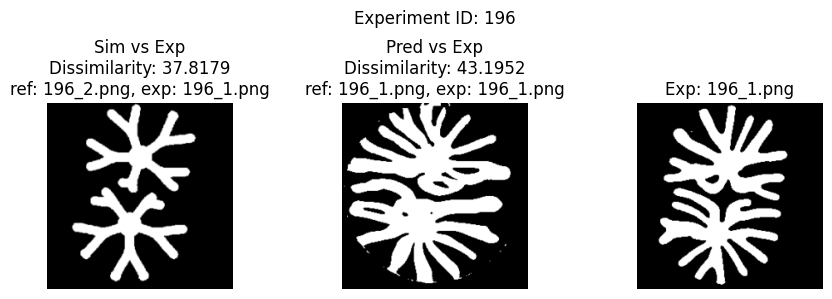

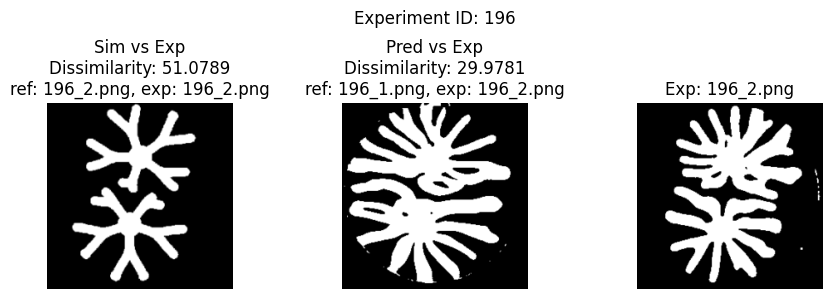

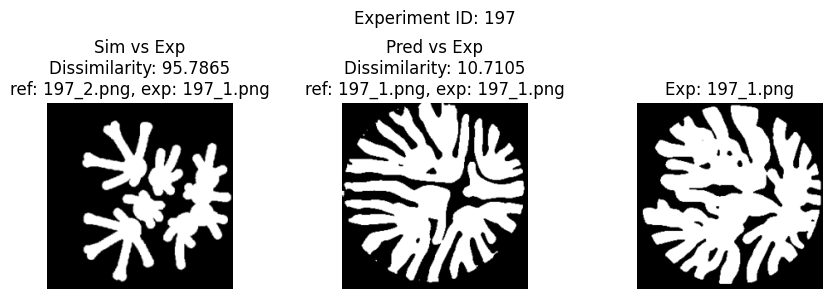

In [27]:
# All inputs below were prepared once with the ORIGINAL black-background functions.
# The existing seeded within-configuration reference rule is preserved.
alldata_exp_sorted = sorted(alldata_exp_black)
sim_exp_dataset = FixedPairDataset(exp_files=alldata_exp_sorted, ref_files=alldata_sim_black,
    transform=transform, seed=42, preprocess_func_1=None, preprocess_func_2=None)
pred_exp_dataset = FixedPairDataset(exp_files=alldata_exp_sorted, ref_files=alldata_pred,
    transform=transform, seed=42, preprocess_func_1=None, preprocess_func_2=None)
sim_exp_loader = DataLoader(sim_exp_dataset, batch_size=1, shuffle=False)
pred_exp_loader = DataLoader(pred_exp_dataset, batch_size=1, shuffle=False)
print(f'Total experimental images paired: {len(sim_exp_dataset)} (simulation), {len(pred_exp_dataset)} (prediction)')
output_dir = str(RESULTS_DIR / 'plots/cross_source_examples')
Path(output_dir).mkdir(exist_ok=True)
sim_score_list, pred_score_list = compare_and_plot_by_index(
    model, sim_exp_dataset, pred_exp_dataset, device, output_dir,
    num_pairs=len(sim_exp_dataset), max_previews=MAX_PAIR_PREVIEWS)
assert len(sim_score_list) == len(pred_score_list) == 132

Simulations closer or approximately equal to experiments than predictions for : 67 out of 132


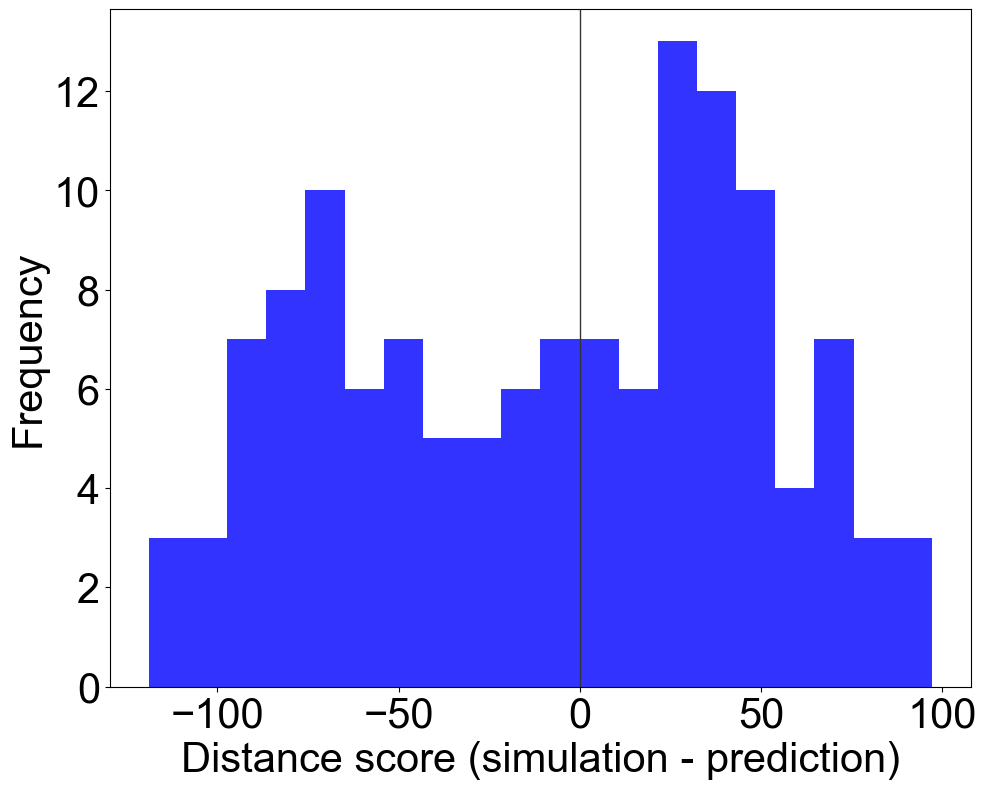

In [28]:
# Plot the histograms of distance differences
diff_list = [sim_score_list[i] - pred_score_list[i] for i in range(len(pred_score_list))]
count_sim_greater_or_close = sum(
    (sim < pred) or abs(sim - pred) < 0.05
    for sim, pred in zip(sim_score_list, pred_score_list)
)
print(f"Simulations closer or approximately equal to experiments than predictions for : {count_sim_greater_or_close} out of {len(sim_score_list)}")


plt.figure(figsize=(10,8))
plt.hist(diff_list, bins=20, color='blue', alpha=0.8)
plt.axvline(x=0, color=(0.2, 0.2, 0.2), linestyle='-', linewidth=1)
plt.xlabel("Distance score (simulation - prediction)",fontproperties=prop)
plt.ylabel("Frequency",fontproperties=prop)
plt.xticks(fontproperties=prop)
plt.yticks(fontproperties=prop)


plt.tight_layout()
# plt.xlim(-2,2)
filename=os.path.join(OUTPUT_DIR_CONTRASTIVE_LEARNING, "sim-pred_hist.png")
plt.savefig(filename)
plt.show()


In [29]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Supp. Fig. 21 — simulation/prediction distance differences
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'sim_to_exp_diffusion' / 'vector based plots'

# Replot the existing diff_list only.
_vector_fig = plt.figure(figsize=(10,8))
plt.hist(diff_list, bins=20, color='blue', alpha=0.8)
plt.axvline(x=0, color=(0.2, 0.2, 0.2), linestyle='-', linewidth=1)
plt.xlabel("Distance score (simulation - prediction)",fontproperties=prop)
plt.ylabel("Frequency",fontproperties=prop)
plt.xticks(fontproperties=prop)
plt.yticks(fontproperties=prop)


plt.tight_layout()
# plt.xlim(-2,2)
filename=os.path.join(OUTPUT_DIR_CONTRASTIVE_LEARNING, "sim-pred_hist.png")
save_vector_pdf(_vector_fig, VECTOR_DIR / 'SuppFig21_distance_difference_histogram.pdf')
plt.close(_vector_fig)


import numpy as np
import csv

# Record each selected reference and score; no comparisons disappear silently.
source_by_id = {row['image_id']: row for row in prepared_manifest}
cross_rows = []
for index, (sim_pair, pred_pair) in enumerate(zip(sim_exp_dataset.pairs, pred_exp_dataset.pairs)):
    sim_ref, exp_path = sim_pair
    pred_ref, pred_exp_path = pred_pair
    image_id = Path(exp_path).stem
    assert image_id == Path(pred_exp_path).stem
    row = source_by_id[image_id]
    cross_rows.append(dict(image_id=image_id, subset=row['subset'],
        configuration_id=row['configuration_id'], experiment_path=exp_path,
        simulation_reference=sim_ref, prediction_reference=pred_ref,
        simulation_distance=sim_score_list[index], prediction_distance=pred_score_list[index],
        difference=diff_list[index]))
write_csv(_figure_source_path(RESULTS_DIR / 'cross_source_scores.csv'), cross_rows)
summary_rows = []
for subset in ['all', 'primary', 'fixed']:
    rows = [row for row in cross_rows if subset == 'all' or row['subset'] == subset]
    differences = np.array([row['difference'] for row in rows])
    summary_rows.append(dict(subset=subset, n_images=len(rows),
        prediction_closer=int((differences > 0).sum()),
        simulation_closer=int((differences < 0).sum()), ties=int((differences == 0).sum()),
        prediction_closer_fraction=float((differences > 0).mean()),
        mean_distance_difference=float(differences.mean())))
write_csv(_figure_source_path(RESULTS_DIR / 'cross_source_summary.csv'), summary_rows)

# All evaluation loaders are ordered. Label-specific arrays can therefore be
# linked back to their exact image pairs, even though figures group by label.
pair_score_rows = []
variants = [
    ('experiment_grayscale', exp_dataset_color, scores_0a, scores_1a),
    ('experiment_binary_white', exp_dataset, scores_0b, scores_1b),
    ('prediction_grayscale', pred_dataset_color, scores_0d, scores_1d),
    ('prediction_binary_black', pred_dataset, scores_0c, scores_1c),
]
for variant, dataset, negatives, positives in variants:
    cursors = {0: 0, 1: 0}
    values = {0: negatives, 1: positives}
    for pair, label in zip(dataset.pairs, dataset.labels):
        first, second = pair
        score = values[label][cursors[label]]
        cursors[label] += 1
        first_id, second_id = Path(first).stem, Path(second).stem
        assert (configuration_id(first) == configuration_id(second)) == bool(label)
        pair_score_rows.append(dict(variant=variant,
            subset=source_by_id[first_id]['subset'], label=label,
            first_image_id=first_id, second_image_id=second_id,
            first_configuration_id=configuration_id(first),
            second_configuration_id=configuration_id(second),
            distance=float(score)))
write_csv(_figure_source_path(RESULTS_DIR / 'replicate_pair_scores.csv'), pair_score_rows)
np.savez_compressed(_figure_source_path(RESULTS_DIR / 'SuppFig20_scores.npz'),
    scores_0a=scores_0a, scores_1a=scores_1a, scores_0b=scores_0b, scores_1b=scores_1b,
    scores_0c=scores_0c, scores_1c=scores_1c, scores_0d=scores_0d, scores_1d=scores_1d)
np.savez_compressed(_figure_source_path(RESULTS_DIR / 'SuppFig21_scores.npz'), simulation=sim_score_list,
    prediction=pred_score_list, difference=diff_list)
assert sha256(model_path) == checkpoint_hash_before
assert sha256(preparation_settings['preprocess_module']) == preparation_settings['preprocess_source_sha256_before']
settings = dict(
    source_notebook='DissimilarityScore_Seeding.ipynb', training_run=RUN_TRAINING,
    checkpoint=model_path, checkpoint_sha256=checkpoint_hash_before,
    n_images=132, n_configurations=67, primary_images=96, fixed_images=36,
    replicated_configurations=65, similar_pairs_per_variant=65, dissimilar_pairs_per_variant=65,
    singleton_images=preparation_settings['singleton_images'],
    preprocessing_source_unchanged=True, original_preprocessing_defaults_preserved=True,
    prepared_input_manifest=str(_figure_source_path(RESULTS_DIR / 'prepared_manifest.csv')),
    replicate_pairing='Original balanced sampling applied separately to primary/fixed cohorts, seed 0; same-configuration label 1',
    cross_source_pairing='Original within-configuration random reference selection, seed 42; primary file/pool order retained',
    siamese_input_transform='Original torchvision Resize((224,224)) and ToTensor',
    distance='Euclidean F.pairwise_distance (p=2)',
    primary_reference_order_preserved=True, summary=summary_rows)
(_figure_source_path(RESULTS_DIR / 'evaluation_settings.json')).write_text(json.dumps(settings, indent=2) + '\n')
print('Full-cohort cross-source results:')
for row in summary_rows:
    print(row)
print('Saved scores and preprocessing/checkpoint provenance to', RESULTS_DIR)

Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig21_distance_difference_histogram.pdf
Full-cohort cross-source results:
{'subset': 'all', 'n_images': 132, 'prediction_closer': 65, 'simulation_closer': 67, 'ties': 0, 'prediction_closer_fraction': 0.49242424242424243, 'mean_distance_difference': -8.281783299012618}
{'subset': 'primary', 'n_images': 96, 'prediction_closer': 32, 'simulation_closer': 64, 'ties': 0, 'prediction_closer_fraction': 0.3333333333333333, 'mean_distance_difference': -24.56159404416879}
{'subset': 'fixed', 'n_images': 36, 'prediction_closer': 33, 'simulation_closer': 3, 'ties': 0, 'prediction_closer_fraction': 0.9166666666666666, 'mean_distance_difference': 35.131045354737175}
Saved scores and preprocessing/checkpoint provenance to /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/controlnet_essential/siamese_full_test_132
